In [114]:
from pathlib import Path
from html import unescape
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow import keras
from tensorflow.keras.datasets import imdb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [115]:
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 25000
Testing samples: 25000


In [116]:
print("First review:")
print(X_train[0])

print("\nFirst label:")
print(y_train[0])

print("\nLength of first review:")
print(len(X_train[0]))

First review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]

First label:
1

Length of first review:
218


In [117]:
print("Positive reviews:", np.sum(y_train == 1))
print("Negative reviews:", np.sum(y_train == 0))


Positive reviews: 12500
Negative reviews: 12500


In [145]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_length = 200

X_train_padded = pad_sequences(
    X_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_padded = pad_sequences(
    X_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("X_train_padded shape:", X_train_padded.shape)
print("X_test_padded shape:", X_test_padded.shape)

X_train_padded shape: (25000, 200)
X_test_padded shape: (25000, 200)


In [146]:
review_lengths = [len(review) for review in X_train]

print("Minimum:", min(review_lengths))
print("Maximum:", max(review_lengths))
print("Average:", sum(review_lengths) / len(review_lengths))

Minimum: 11
Maximum: 2494
Average: 238.71364


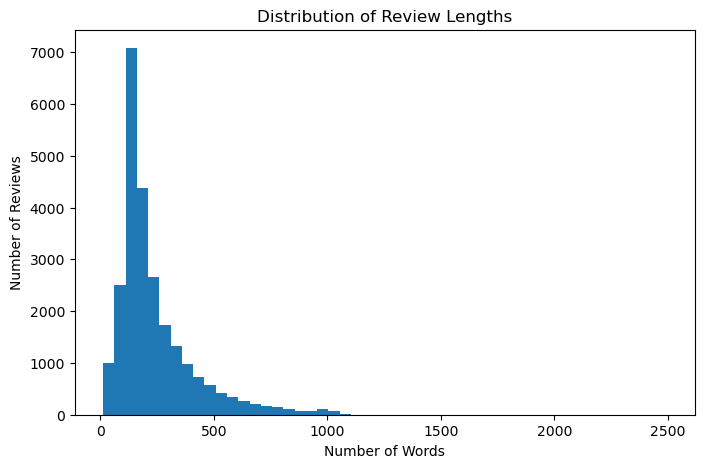

In [147]:
plt.figure(figsize=(8,5))

plt.hist(
    review_lengths,
    bins=50
)

plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Review Lengths")

plt.show()

In [148]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout

In [149]:
# Analyze Review Length by Sentiment

positive_lengths = [
    len(X_train[i])
    for i in range(len(X_train))
    if y_train[i] == 1
]

negative_lengths = [
    len(X_train[i])
    for i in range(len(X_train))
    if y_train[i] == 0
]

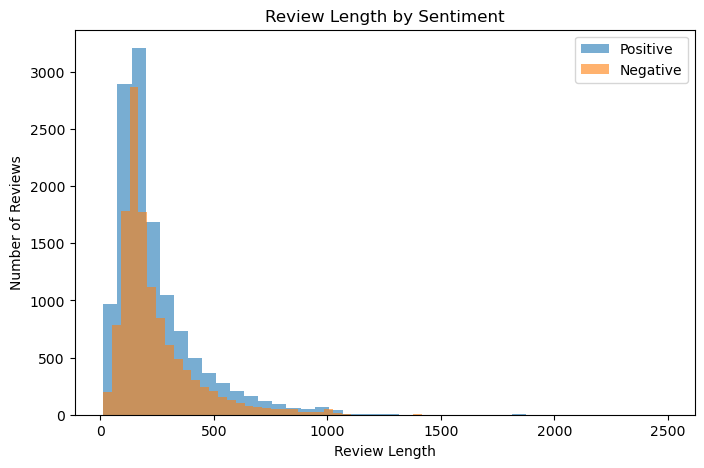

In [150]:
plt.figure(figsize=(8,5))

plt.hist(
    positive_lengths,
    bins=40,
    alpha=0.6,
    label="Positive"
)

plt.hist(
    negative_lengths,
    bins=40,
    alpha=0.6,
    label="Negative"
)

plt.xlabel("Review Length")
plt.ylabel("Number of Reviews")
plt.title("Review Length by Sentiment")

plt.legend()
plt.show()

In [151]:
word_index = imdb.get_word_index()

reverse_word_index = {
    value + 3: key
    for key, value in word_index.items()
}

reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"

In [152]:
def decode_review(encoded_review):
    return " ".join(
        reverse_word_index.get(i, "<UNK>")
        for i in encoded_review
    )

In [153]:
print(decode_review(X_train[0]))

<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for wha

In [154]:
from collections import Counter

positive_words = []
negative_words = []

for review, label in zip(X_train, y_train):

    words = [
        reverse_word_index.get(i, "<UNK>")
        for i in review
    ]

    if label == 1:
        positive_words.extend(words)
    else:
        negative_words.extend(words)

In [155]:
# Get Word Frequency

all_text = " ".join(
    decode_review(review)
    for review in X_train
)

words = re.findall(
    r'\b[a-zA-Z]+\b',
    all_text.lower()
)

word_counts = Counter(words)

print(word_counts.most_common(20))

[('unk', 341611), ('the', 336696), ('and', 164097), ('a', 163082), ('of', 145847), ('to', 135708), ('is', 107313), ('br', 101871), ('it', 96382), ('in', 93934), ('i', 87590), ('this', 75974), ('that', 73230), ('was', 48195), ('as', 46927), ('for', 44335), ('with', 44122), ('movie', 43987), ('but', 42594), ('s', 42458)]


In [156]:
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in words
    if word not in stop_words
]

word_counts = Counter(filtered_words)

print(word_counts.most_common(20))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sulai\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


[('unk', 341611), ('br', 101871), ('movie', 43987), ('film', 40128), ('one', 26765), ('start', 26697), ('like', 20272), ('good', 15100), ('time', 12682), ('even', 12650), ('would', 12433), ('story', 11948), ('really', 11734), ('see', 11460), ('well', 10644), ('much', 9758), ('people', 9271), ('bad', 9270), ('get', 9269), ('also', 9157)]


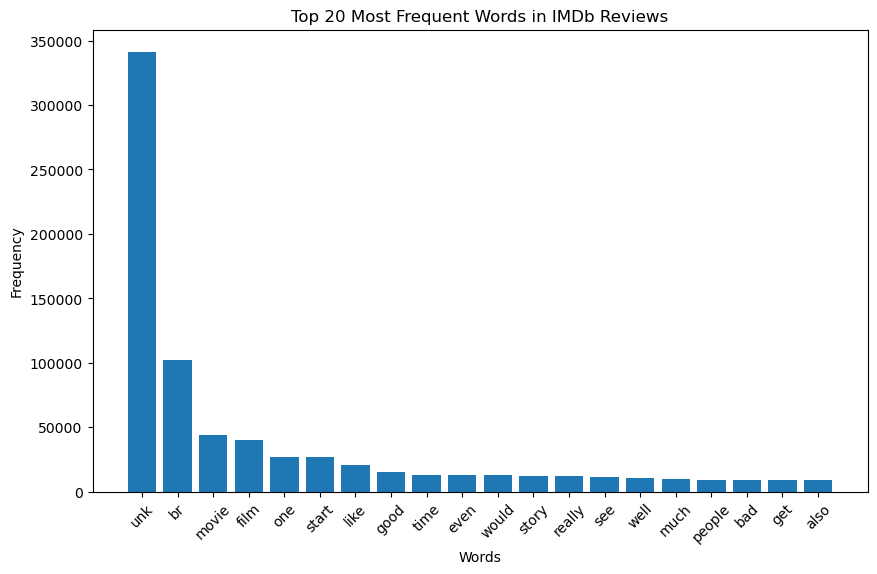

In [157]:
top_words = word_counts.most_common(20)

words = [item[0] for item in top_words]
counts = [item[1] for item in top_words]

plt.figure(figsize=(10, 6))

plt.bar(words, counts)

plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Top 20 Most Frequent Words in IMDb Reviews")

plt.xticks(rotation=45)

plt.show()

In [158]:
positive_word_counts = Counter(positive_words)
negative_word_counts = Counter(negative_words)

In [159]:
print("Top Positive Words:")

for word, count in positive_word_counts.most_common(20):
    print(word, ":", count)

Top Positive Words:
<UNK> : 180713
the : 172990
and : 89719
a : 83668
of : 76850
to : 66735
is : 57238
in : 50196
br : 49235
it : 39365
i : 36296
this : 35071
that : 34209
as : 26304
with : 23245
for : 22412
was : 21910
but : 20818
film : 20366
movie : 18855


In [160]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("First review:")
print(X_train[0])

print("First label:")
print(y_train[0])

Training data shape: (25000,)
Testing data shape: (25000,)
First review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 

In [161]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dropout, Dense

In [162]:
vocab_size = 10000
embedding_dim = 128
rnn_units = 64
max_length = 200

model = Sequential([
    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    SimpleRNN(rnn_units),

    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)              │ (None, 200, 128)            │       1,280,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_5 (SimpleRNN)             │ (None, 64)                  │          12,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,292,417 (4.93 MB)

 Trainable params: 1,292,417 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

In [163]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [164]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [165]:
history = model.fit(
    X_train_padded,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 85ms/step - accuracy: 0.6112 - loss: 0.6559 - val_accuracy: 0.7462 - val_loss: 0.5377
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 84ms/step - accuracy: 0.7562 - loss: 0.5234 - val_accuracy: 0.5796 - val_loss: 0.7034
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 87ms/step - accuracy: 0.8443 - loss: 0.3684 - val_accuracy: 0.7750 - val_loss: 0.5401


In [169]:
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.7338 - loss: 0.5425
Test Loss: 0.5425429940223694
Test Accuracy: 0.7337599992752075


In [170]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_probability = model.predict(
    X_test_padded,
    verbose=1
)

# Convert probabilities to 0/1
y_pred = (y_probability >= 0.5).astype(int).flatten()

print("Predictions generated successfully.")

782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step
Predictions generated successfully.


In [171]:
# Calculate classification metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.73376
Precision: 0.7214978775015161
Recall   : 0.76144
F1 Score : 0.7409310291141211


In [172]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.75      0.71      0.73     12500
    Positive       0.72      0.76      0.74     12500

    accuracy                           0.73     25000
   macro avg       0.73      0.73      0.73     25000
weighted avg       0.73      0.73      0.73     25000



In [173]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[8826 3674]
 [2982 9518]]


In [176]:
def preprocess_new_review(review):

    words = review.lower().split()

    encoded_review = []

    for word in words:

        index = word_index.get(word)

        if index is not None and index < 10000:
            encoded_review.append(index + 3)
        else:
            encoded_review.append(2)  # Unknown word

    padded_review = pad_sequences(
        [encoded_review],
        maxlen=200,
        padding="post",
        truncating="post"
    )

    return padded_review
    

In [177]:
def predict_sentiment(review):

    processed_review = preprocess_new_review(review)

    probability = model.predict(
        processed_review,
        verbose=0
    )[0][0]

    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability
    else:
        sentiment = "Negative"
        confidence = 1 - probability

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Confidence:", f"{confidence:.2%}")

In [178]:
review = "This movie was amazing and I really enjoyed it."

predict_sentiment(review)

Review: This movie was amazing and I really enjoyed it.
Sentiment: Positive
Confidence: 62.89%


In [179]:
review = "This movie was boring, disappointing and terrible."

predict_sentiment(review)

Review: This movie was boring, disappointing and terrible.
Sentiment: Negative
Confidence: 58.55%


In [181]:
model.save("imdb_rnn_sentiment_model.keras")

In [182]:
from tensorflow.keras.datasets import imdb
import json

word_index = imdb.get_word_index()

with open("word_index.json", "w") as f:
    json.dump(word_index, f)

print("word_index.json saved successfully!")

word_index.json saved successfully!
